In [1]:
#%pip install git+https://github.com/XanaduAI/strawberryfields.git


In [2]:
#%pip install "setuptools<82"

# B. Simulation of Gaussian states with Strawberry Fields

Strawberry Fields is an end-to-end Python library for quantum computing and simulation built by Xanadu that is
compatible with continuous-variable (CV) quantum systems. It offers tools for designing, optimizing, and simulating
quantum optical circuits, including the application of models for Gaussian states and operations, as well as non-
Gaussian elements.
Strawberry Fields uses the convention for defining the quadrature operators ($\hat{x}$ and $\hat{p}$) in terms of the bosonic
creation $(\hat{a}^{\dagger})$ and annihilation $(\hat{a})$ operators as:

$$\hat{x} = \sqrt{\frac{\hbar}{2}}(\hat{a}+\hat{a}^{\dagger})$$
$$\hat{p} = -i\sqrt{\frac{\hbar}{2}}(\hat{a}-\hat{a}^{\dagger})$$

By default, the library sets $\hbar$ = 2, but this value can be modified. We will adhere to this convention going forward,
so the values obtained for the mean vector and covariance matrix will correspond to this choice.
In Strawberry Fields, a multi-mode quantum system is represented by a series of nodes ($q_j$) in a quantum circuit.
Each quantum node, such as $q[j]$, corresponds to a specific mode of the system. For example, $q[0]$ represents the
first mode, $q[1]$ the second, and so on. In the simplest case of a single-mode system, you only need one node in your
circuit.

Let us start simulating some common single-mode states.

In [3]:
import strawberryfields as sf
import matplotlib.pyplot as plt
import numpy as np

/home/eve/Documents/TU_Wien/Research/TQO/.venv/lib/python3.13/site-packages/strawberryfields/apps/data/sample.py:20: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


# Single mode states

## Vaccum state $|0 \rangle $

In Strawberry Fields, the default state for any un-acted-upon mode is the vacuum state $|0\rangle$. This is the quantum state with the lowest possible energy and no photons. To create a program with a single mode initialized to the vacuum state, you just need to create a quantum circuit with one mode.

In [4]:
prog = sf.Program(1) # Single mode program

Now we can prepare the vacuum state on this mode:

In [5]:
# Prepare the vacuum state on first mode:
with prog.context as q:
    q[0]

To run the quantum program `prog` using the Gaussian backend, you use the `eng.run()` method. This backend is specifically designed for simulating Gaussian states and operations efficiently.

In [6]:
eng = sf.Engine('gaussian') # Using the Gaussian backend

In [7]:
state = eng.run(prog).state # Run the program to get the state

In Strawberry Fields, you can choose from four primary backends to run your quantum programs, with your choice depending on the specific task.

- **Gaussian backend:** This backend is highly efficient for simulating Gaussian states and operations. It is the default for many introductory simulations.

- **Fock backend:** Use this backend when you need to perform simulations in the Fock basis, which is essential for tasks involving photon number-counting and non-Gaussian operations.

- **Bosonic backend:** This backend is an alternative for simulating photonic systems, offering a different approach to computations compared to the Fock basis.

- **TensorFlow ('tf') backend:** This backend leverages the TensorFlow library to enable the creation of quantum machine learning models.

### Wigner function

The `state` object holds all the physical information of your quantum system. One way to access this information is by obtaining the discretized Wigner function using the `.wigner()` method.

This method takes the quadrature values $(\hat{X},\hat{P}​)$ as arguments and calculates the Wigner function's value at that specific point in phase space.

For example, to get a full plot of the Wigner function, you would pass in a range of values for $\hat{X}$ and $\hat{P}$​, allowing you to visualize the state's quasi-probability distribution.

In [8]:
X = np.linspace(-5, 5, 100) # X values for Wigner function
P = np.linspace(-5, 5, 100) # P values for Wigner function
W = state.wigner(0, X, P) # Wigner function values

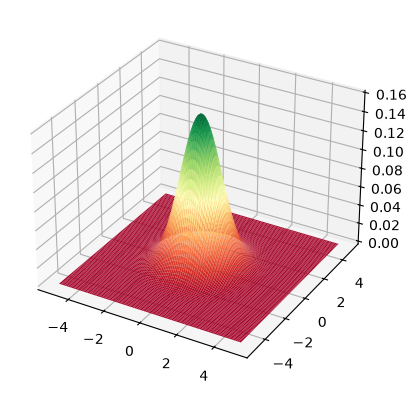

In [9]:
fig = plt.figure() # Create a new figure
X, P = np.meshgrid(X, P) # Create a meshgrid for X and P
ax = fig.add_subplot(111, projection="3d") # 3D subplot
ax.plot_surface(X, P, W, cmap="RdYlGn", lw=0.5, rstride=1, cstride=1) # Surface plot
fig.set_size_inches(4.8, 5) # Set figure size

Starting now, we'll use the `plot_wigner()` function. It takes the state from a Strawberry Fields simulation and generates both surface and contour plots of the Wigner function for that state. For more information, you can find the function's definition below.

In [10]:
def plot_wigner(state):
    """Plots the Wigner function of a given quantum state.

    This function generates and displays two visualizations of the Wigner
    function: a 3D surface plot and a 2D contour plot.

    Args:
        state: A quantum gaussia state object generated with Strawberry Fields.
    """
    # --- Data Generation for Wigner function ---
    X = np.linspace(-5, 5, 100)
    P = np.linspace(-5, 5, 100)
    Z = state.wigner(0, X, P)
    X, P = np.meshgrid(X, P)

    # --- Plotting ---
    # Create a figure to hold the subplots
    fig = plt.figure()
    fig.set_size_inches(10, 5) # Adjusted size for two plots

    # == Subplot 1: Surface Plot ==
    ax1 = fig.add_subplot(1, 2, 1, projection='3d') # 1 row, 2 columns, 1st plot
    ax1.plot_surface(X, P, Z, cmap="RdYlGn", lw=0.5, rstride=1, cstride=1)
    ax1.set_xlabel(r"$\hat{x}$")
    ax1.set_ylabel(r"$\hat{p}$")
    ax1.set_zlabel(r"$W(\hat{x},\hat{p})$")
    ax1.set_title("Surface Plot")

    # == Subplot 2: Contour Plot ==
    ax2 = fig.add_subplot(1, 2, 2) # 1 row, 2 columns, 2nd plot
    contour = ax2.contourf(X, P, Z, cmap="RdYlGn") # Use contourf for filled contours
    fig.colorbar(contour, ax=ax2) # Add a colorbar for the contour plot
    ax2.set_xlabel(r"$\hat{x}$")
    ax2.set_ylabel(r"$\hat{p}$")
    ax2.set_title("Contour Plot")
    ax2.set_aspect('equal') # Ensure the plot is circular, not elliptical

    # Adjust layout and show the plot
    fig.subplots_adjust(wspace=0.4)
    plt.show()

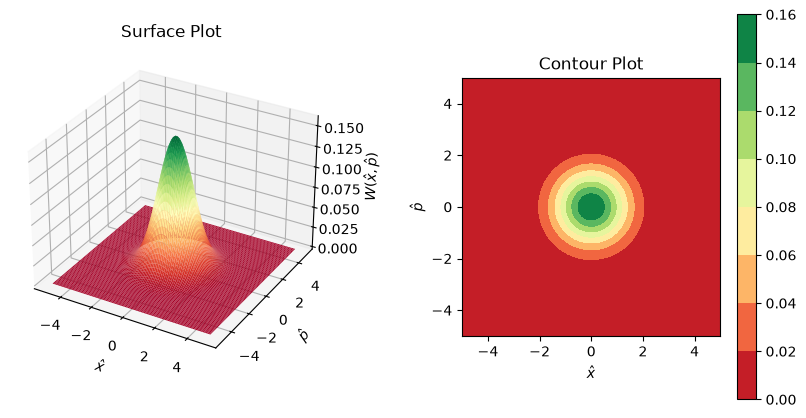

In [11]:
plot_wigner(state)

### Covariance matrix and means vector

As previously noted, all physical information for Gaussian states is encoded in their covariance matrix and mean vector. You can easily retrieve this data from a Strawberry Fields simulation using the `.cov()` and `.means()` functions.

In [12]:
# Get the covariance matrix of the vacuum state
cov_vac = state.cov()
cov_vac

array([[1., 0.],
       [0., 1.]])

In [13]:
# Get the mean values of the vacuum state
mean_vac = state.means()
mean_vac

array([0., 0.])

For vacuum state:
$$
    \overline{\mathbf{r}}=(0,0)^T,\quad \sigma=\left(\begin{array}{cc}1 & 0 \\ 0 & 1 \end{array}\right).
$$

## Coherent state $|\alpha \rangle$

A coherent state, written as $|\alpha \rangle$, is essentially a displaced vacuum state $|0\rangle$. You create it by applying the displacement operator, $\hat{D}(\alpha)$. The amount of displacement in the $\hat{x}$ and $\hat{p}$​ quadratures is directly related to the real and imaginary parts of $\alpha$. To do this in Strawberry Fields, you simply use the `sf.ops.Dgate()` on a vacuum qumode and provide the magnitude and phase of the complex number $\alpha$ as arguments.


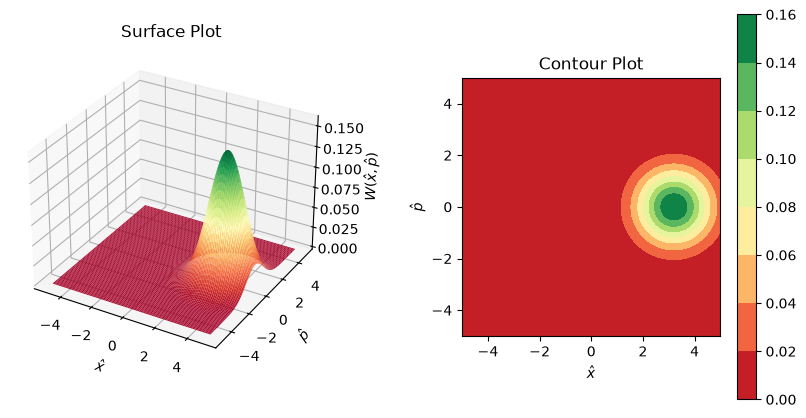

In [14]:
prog = sf.Program(1)
with prog.context as q:
    sf.ops.Dgate(1.6,0) | q[0] # Generates a Coherent state with alpha=1.6 and phase=0

eng.reset()
state = eng.run(prog).state # Run the program to get the state

plot_wigner(state) # Plot the Wigner function of the coherent state

### Covariance matrix and means vector

In [15]:
cov_coh = state.cov()
cov_coh

array([[1., 0.],
       [0., 1.]])

In [16]:
mean_coh = state.means()
mean_coh

array([3.2, 0. ])

For coherent state:
$$
    \overline{\mathbf{r}}=(3.2,0)^T,\quad \sigma=\left(\begin{array}{cc}1 & 0 \\ 0 & 1 \end{array}\right).
$$

## Squeezed vacuum state $|\xi \rangle$

The squeezed state $|\xi\rangle$ is the result of applying the squeeze operator $\hat{S}(\xi)$ to the vacuum state $|0\rangle$. In Strawberry Fields, you can generate this state using the `sf.ops.Sgate()` on a vacuum qumode. This gate takes the magnitude and phase of the complex squeezing parameter $\xi$ as its arguments.

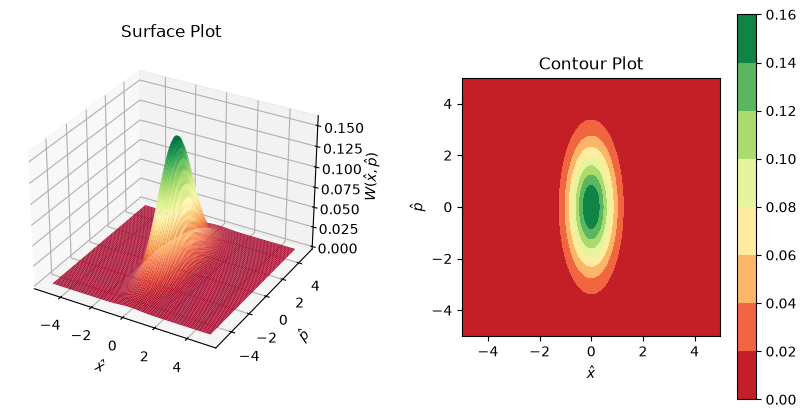

In [17]:
prog = sf.Program(1)
with prog.context as q:
    sf.ops.Sgate(0.5) | q[0] # Squeezing with r=0.5 and phi=0

eng.reset()
state = eng.run(prog).state # Run the program to get the state
plot_wigner(state) # Plot the Wigner function of the squeezed state

### Covariance matrix and means vector

In [18]:
cov_sqz = state.cov()
cov_sqz

array([[0.36787944, 0.        ],
       [0.        , 2.71828183]])

In [19]:
mean_sqz = state.means()
mean_sqz

array([0., 0.])

For squeezed state:
$$
    \overline{\mathbf{r}}=(0,0)^T,\quad \sigma=\left(\begin{array}{cc}0.36787944 & 0 \\ 0 & 2.71828183 \end{array}\right).
$$

## Displaced squeezed state $|\alpha ,\xi \rangle$

We can displace and squeeze the vacuum state. For instance, we can first apply a displacement with parameter $\alpha = 1.6 e^{i\frac{\pi}{4}}$, then a squeeze operation with parameter of $\xi  = 0.5 e^{i\frac{\pi}{2}}$.

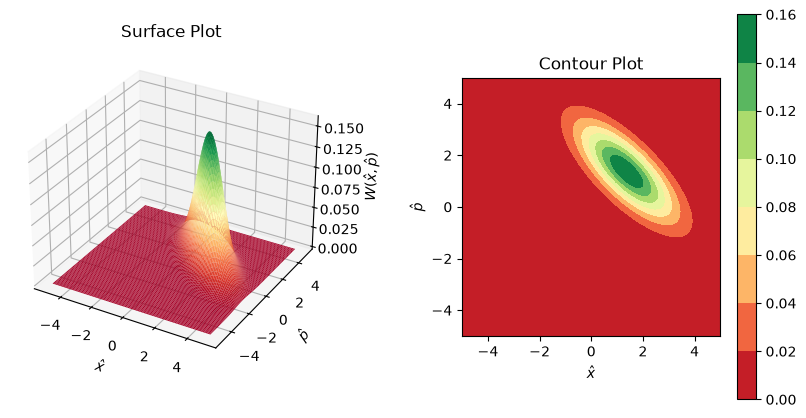

In [20]:
prog = sf.Program(1)
with prog.context as q:
    sf.ops.Dgate(1.6,np.pi/4) | q[0] # Displacement with alpha=1.6 and phase=pi/4
    sf.ops.Sgate(0.5,np.pi/2) | q[0] # Squeezing with r=0.5 and phi=pi/2

eng.reset()
state = eng.run(prog).state # Run the program to get the state
plot_wigner(state) # Plot the Wigner function of the displaced-squeezed state

### Covariance matrix and means vector

In [21]:
cov_ds = state.cov()
cov_ds

array([[ 1.54308063, -1.17520119],
       [-1.17520119,  1.54308063]])

In [22]:
mean_ds = state.means()
mean_ds

array([1.37242222, 1.37242222])

For displaced squeezed state:
$$
    \overline{\mathbf{r}}=(1.37242222,1.37242222)^T,\quad \sigma=\left(\begin{array}{cc}1.54308063 & -1.17520119 \\ -1.17520119 & 1.54308063 \end{array}\right).
$$

# Two mode states

We can also create a two mode vacuum state with Strawberry Fields and print its covariance matrix and means vector.
Let us create a two mode vaccum state:

In [23]:
prog = sf.Program(2)

with prog.context as q:

    q[0]
    q[1]

eng = sf.Engine("gaussian")
state=eng.run(prog).state

In [24]:
cov_mtx = state.cov()
cov_mtx

array([[1., 0., 0., 0.],
       [0., 1., 0., 0.],
       [0., 0., 1., 0.],
       [0., 0., 0., 1.]])

In [25]:
means=state.means()
means

array([0., 0., 0., 0.])

Let us generate a two mode coherent state with the first mode in a coherent state with parameter $\alpha = 1.6$ and the second mode in a vacuum state.

In [26]:
prog = sf.Program(2)

with prog.context as q:

    sf.ops.Dgate(1.6,0) | q[0]
    # If we don't assign any state on the second mode, it will be a vacuum state by default

eng = sf.Engine("gaussian")
state=eng.run(prog).state

cov_mtx = state.cov()
cov_mtx

array([[1., 0., 0., 0.],
       [0., 1., 0., 0.],
       [0., 0., 1., 0.],
       [0., 0., 0., 1.]])

In [27]:
means=state.means()
means

array([3.2, 0. , 0. , 0. ])

Here it is worth noting that the library uses representation of the 2N-operator vector, denoted by $\hat{\boldsymbol{r}} = (\hat{x_1},\dots,\hat{x_N} ,\hat{p_1}\dots,\hat{p_N})^T$, which is commonly referred to as the \textit{xp-order}.
In Sec. \ref{sec:gaussianiry} we have worked with the representation $\boldsymbol{\hat{r}}=( \hat{x}_1, \hat{p}_1,\dots,\hat{x}_N, \hat{p}_N)^T$. As a consequence, the order of covariance matrix elements also differs from the ones obtained in Strawberry Fields.
We can apply a basis transformation to go from the \textit{xp-order} to the other one using the permutation matrix ($\Pi$) that flips the elements of $(\hat{x_1},\dots,\hat{x_N} ,\hat{p_1}\dots,\hat{p_N})^T$ to $( \hat{x}_1, \hat{p}_1,\dots,\hat{x}_N, \hat{p}_N)^T$

The change of basis is as follows:
\begin{equation}
\begin{split}
&\boldsymbol{\hat{r}} \rightarrow \Pi \cdot \hat{r} \\
&\sigma \rightarrow \Pi \cdot \sigma \cdot \Pi,
\end{split}
\end{equation}

From now on, we are going to work with the representation in which the $\boldsymbol{\hat{r}}$ vector is written as $\boldsymbol{\hat{r}}=( \hat{x}_1, \hat{p}_1,\dots,\hat{x}_N, \hat{p}_N)^T$. We implemented the functions `COB_CovMtx()` and `COB_Means()` that implement this change of basis. They receive as an argument the means vector and the covariance matrix that SF returns respectively.

In [28]:
def Bj(matrix):
    """Calculate the permuatation matrix associated with the transformation """


    size, _ = matrix.shape

    # Create a sample matrix
    matrix = np.eye(size)

    # Split the matrix vertically into two sub-matrices
    matrix1, matrix2 = np.split(matrix, 2, axis=1)


    a0=np.vstack(([row[0] for row in matrix1],[row[0] for row in matrix2]))
    # Create a zeros matriz of shape size x size
    #Bj=np.zeros((size,size))
    for i in range((size//2)-1):
        a=np.vstack(([row[i+1] for row in matrix1],[row[i+1] for row in matrix2]))
        a0=np.vstack((a0,a))

    Bj=a0.transpose()

    return Bj


def COB_CovMtx(cov_mtx):
    """Transform the Covariance Matrix  """


    # SF defines vector of quadrature operator as r=(x1,x2,...,xn,p1,p2,...,pn)
    # We want to work with thw quadrature operator as r=(x1,p1,...,xn,pn)
    # Then, we should do a basis transfromation


    #Apply transfromation of basis of Covariance Matrix (V) from to (Bj^-1*V*Bj)
    cov_mtx2 = np.linalg.inv(Bj(cov_mtx)) @ cov_mtx @ Bj(cov_mtx)

    return cov_mtx2


def COB_Means(means):
    """Transform the means vector """

    # SF defines vector of quadrature operator as r=(x1,x2,...,xn,p1,p2,...,pn)
    # We want to work with the quadrature operator as r=(x1,p1,...,xn,pn)
    # Then, we should do a basis transfromation


    # Create a matrix to use the sizes on Bj() function
    matrix=np.eye(means.size)

    # #Transform vector of means (<r>) to (Bj^-1*<r>)
    means2 = np.linalg.inv(Bj(matrix)) @ means

    return  means2

Now, we can generate a two mode quantum state where the first mode is in a vacuum state and the second mode is a squeezed state with squeezing parameter $\xi = 0$.

In [29]:
prog = sf.Program(2)

with prog.context as q:

    sf.ops.Sgate(0.5,0) | q[0]  #squeezing  along x (phase = 0)
    # If we don't assign any state on the second mode, it will be a vacuum state by default

eng = sf.Engine("gaussian")
state=eng.run(prog).state

cov_mtx = state.cov()
cov_mtx

array([[0.36787944, 0.        , 0.        , 0.        ],
       [0.        , 1.        , 0.        , 0.        ],
       [0.        , 0.        , 2.71828183, 0.        ],
       [0.        , 0.        , 0.        , 1.        ]])

Then, we can use the function created to express the covariance matrix in the desired basis

In [30]:
COB_CovMtx(cov_mtx)

array([[0.36787944, 0.        , 0.        , 0.        ],
       [0.        , 2.71828183, 0.        , 0.        ],
       [0.        , 0.        , 1.        , 0.        ],
       [0.        , 0.        , 0.        , 1.        ]])

With this representation the covariance matrix for any two mode quantum state is given by the following block matrix:

\begin{equation}
\sigma=\left(\begin{array}{cc}\sigma_{A} & \sigma_{AB} \\ \sigma_{AB}^T & \sigma_{B}\end{array}\right),    
\end{equation}


* $\sigma_{A}$ is the local reduced covariance matrix for mode 1. For a two-mode system, it's a 2$\times$2 matrix that describes the variances and correlations within the first mode alone.
* $\sigma_{B}$ is the local reduced covariance matrix for mode 2. Similarly, for a two-mode system, it's a 2$\times$2 matrix describing the variances and correlations within the second mode.
* $\sigma_{AB}$ is a $2\times2$ matrix that contains the inter-modal correlations between mode 1 and mode 2. It's often referred to as the correlation matrix.

This block matrix structure is a standard and powerful way to represent the statistical properties of multi-mode Gaussian states, such as vacuum, coherent, and squeezed states. It cleanly separates the properties of each individual mode from the correlations that may exist between them, which are crucial for phenomena like entanglement.

# Beam splitter transformation

You may have noticed that the off-diagonal sub-block matrix, $\sigma_{AB}$, was a zero matrix in our previous examples. This indicates that there are no correlations between the two modes. This result is expected because we generated the modes independently. We created one mode as a squeezed state and the other as a vacuum state, with no interaction or shared history between them. Later, we will see that these inter-modal correlation elements play a crucial role in analyzing the nature of correlations between modes, particularly in the context of entanglement.
A typical way to introduce correlations between two independent quantum modes is by interfering them through a beam splitter as explained on Sec. \ref{sec:BS_transf}.
The Strawberry Fields library provides a function for this transformation: `sf.ops.BSgate()`.
It receives as arguments the $\theta$ and $\phi$ parameters of the beam splitter.
For a typical 50/50 beam splitter, the parameters are $\theta = \frac{\pi}{4}$ and $\phi = 0$.

For example, we can apply a 50/50 beam splitter operation to a squeezed state with $\xi = 0.5$ and a vacuum state.

In [31]:
prog = sf.Program(2)

with prog.context as q:


    sf.ops.Sgate(0.5,0) | q[0]


    #Mix squeezed mode and vaccum q[1] on a Beam-splitter
    sf.ops.BSgate(theta=np.pi/4, phi=0) | (q[0],q[1])

eng = sf.Engine("gaussian")
state=eng.run(prog).state

xp_cov_sqz = state.cov()
cov_mtx_sqz = COB_CovMtx(xp_cov_sqz)
cov_mtx_sqz

array([[ 0.68393972,  0.        , -0.31606028,  0.        ],
       [ 0.        ,  1.85914091,  0.        ,  0.85914091],
       [-0.31606028,  0.        ,  0.68393972,  0.        ],
       [ 0.        ,  0.85914091,  0.        ,  1.85914091]])

It is not difficult to implement a function that takes a two-mode covariance matrix $\sigma$ in its block form

\begin{equation*}
\sigma=\left(\begin{array}{cc}\sigma_{A} & \sigma_{AB} \\ \sigma_{AB}^T & \sigma_{B}\end{array}\right),    
\end{equation*}

and check for separability of two-mode systems by applying the Simon criterion

In [32]:
def split(array, nrows, ncols):
    """Split a matrix into sub-matrices."""

    r, h = array.shape
    return (array.reshape(h//nrows, nrows, -1, ncols)
                 .swapaxes(1, 2)
                 .reshape(-1, nrows, ncols))


def SimonCriterion(covariance_mtx, hbar):
    """Apply Simon criterion to a two-mode system"""

    hbar2=hbar**2

    A, C, Ct, B =  split(covariance_mtx, 2, 2)
    J=np.array([[0,1],[-1,0]])

    left= np.linalg.det(A)*np.linalg.det(B)+ ((hbar2/4)-abs(np.linalg.det(C)))**2 - \
        np.trace(A@J@C@J@B@J@Ct@J)
    right= (hbar2/4)*(np.linalg.det(A)+np.linalg.det(B))

    if left >= right:
        print("The bipartite system is separable")

    else:
        print("The bipartite system is entangled")

The entanglement generated by the interference of two independent squeezed vacuum states on a 50:50 beam splitter can be analysed by examining the output correlations using the Simon criterion.
The first input port is injected with a squeezed vacuum state characterised by a squeezing parameter $\xi_1 = 0.5$.
The second input port receives a phase-shifted squeezed vacuum state with a squeezing parameter $\xi_2 = 0.5 e^{i\pi}$.

In [33]:
prog = sf.Program(2)

with prog.context as q:


    sf.ops.Sgate(0.5,0) | q[0]
    sf.ops.Sgate(0.5,np.pi) | q[1]


    #Mix squeezed mode and vaccum q[1] on a Beam-splitter
    sf.ops.BSgate(theta=np.pi/4, phi=0) | (q[0],q[1])

eng = sf.Engine("gaussian")
state=eng.run(prog).state

xp_cov_tmsv = state.cov()
cov_mtx_tmsv = COB_CovMtx(xp_cov_tmsv)

Applying the Simon criterion we check the output modes are entangled

In [34]:
SimonCriterion(cov_mtx_tmsv, hbar=2)

The bipartite system is entangled


# Logarithmic negativity

The Walrus, a library developed by Xanadu, provides a convenient function to calculate the logarithmic negativity.
The `log_negativity()` function from the `thewalrus.quantum` module can compute the logarithmic negativity directly from a covariance matrix.
The result this function returns is calculated using the natural logarithm.
To convert it to base 2 we should divide it by $\ln2$.

We will calculate the logarithmic negativity for the state generated by mixing  a squeezed vacuum with parameter $\xi = 0.5$ and a squeezed vacuum with $\xi = 0.5 e^{i\pi}$ on a beam splitter.

In [35]:
from thewalrus.quantum import log_negativity

En_tsmv=log_negativity(xp_cov_tmsv, split=1)/np.log(2)
print("The logarithmic negativity of the system is:", En_tsmv)

The logarithmic negativity of the system is: 1.4426950408889632


Because this value is greater than zero, we can conclude that the beam splitter's output modes are entangled.

# Reduced states

The covariance matrix and the vector of means of a multimode Gaussian system contain its complete physical information.
To analyze a specific mode or a subset of modes, one must obtain the reduced state of the system.
This process involves tracing out the degrees of freedom of the unwanted modes.
In the `Strawberry Fields` library, this is implemented via the `reduced_gaussian()` function.
This function accepts the indices of the modes of interest as arguments and returns the corresponding reduced means vector and covariance matrix.
We shall analyze the reduced states resulting from the interference of two squeezed vacuum states with squeezing parameters $\xi = 0.5$ and $\xi = 0.5 e^{i\pi}$ on a balanced beam splitter.

The first reduced mode yields the following means vector:

In [36]:
red_mean1, red_cov1 = state.reduced_gaussian([0])
print(red_mean1)

[0. 0.]


And the corresponding covariance matrix:

In [37]:
print(red_cov1)

[[ 1.54308063e+00 -7.19603190e-17]
 [-7.19603190e-17  1.54308063e+00]]


Computing the covariance matrix and means vector for the second mode yields identical results.
The symmetry of the covariance matrix, characterised by equal diagonal elements and vanishing correlations, indicates that the reduced states of this squeezed mixture are thermal states.

# Optical network

Now, we can simulate and characterise quantum correlations in optical networks using the computational tools studied.
Here we construct an optical network consisting of a four-mode Gaussian state and three 50-50 beam splitters as depicted in the below figure.
Then, we mixed the resulting output modes of the first beam splitter with two vacuum modes using the other two beam splitters.

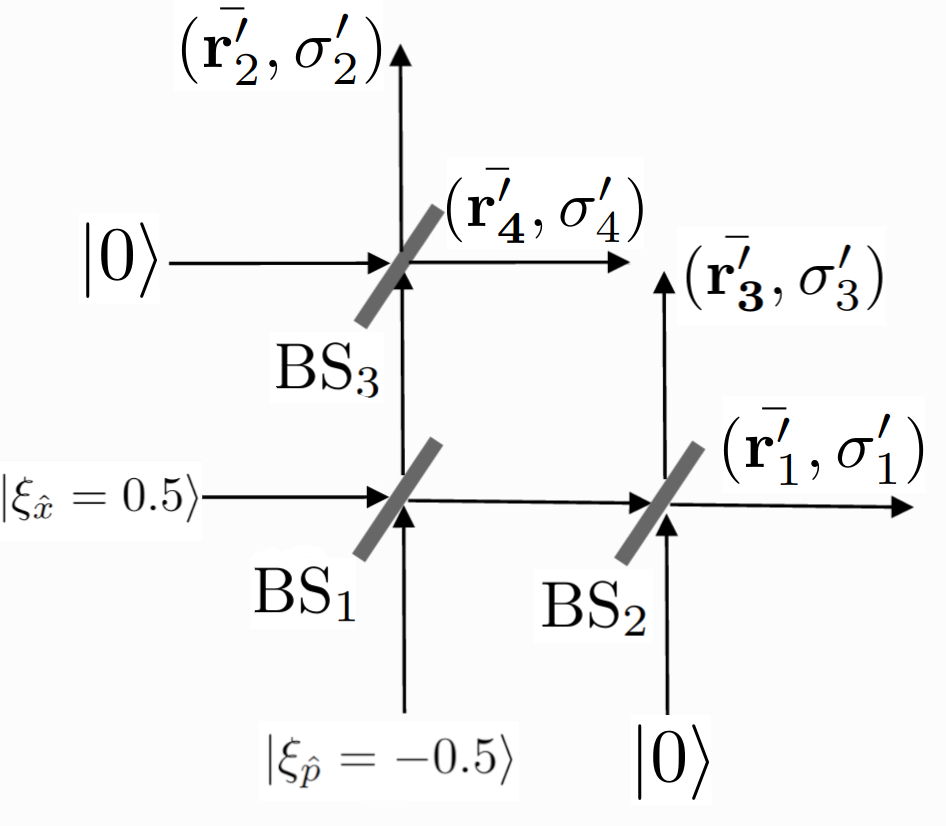

## Step by step

1. Mix two initial squeezed modes.

In [38]:
prog = sf.Program(4)

with prog.context as q:

    sf.ops.Squeezed(r=0.5, p=0) | q[0]  #squeezing  along x (phase = 0)
    sf.ops.Squeezed(r=0.5, p=np.pi) | q[1]  #squeezing  along p (phase = pi)

    #Mix squeezed mode and vaccum q[1] on a Beam-splitter
    sf.ops.BSgate(theta=np.pi/4, phi=0) | (q[0],q[1])

2. Mix the resulting output modes of the first beam splitter with two vacuum modes using the other two beam splitters.

In [39]:
with prog.context as q:

    #Mix the first ouput mode with vaccum q[2] on a Beam-splitter
    sf.ops.BSgate(theta=np.pi/4, phi=0) | (q[0],q[2])
    #Mix the second ouput mode with vaccum q[3] on a Beam-splitter
    sf.ops.BSgate(theta=np.pi/4, phi=0) | (q[1],q[3])

3. Store the final covariance matrix for the four-mode Gaussian state obtained after the action of the three beam splitters.

In [40]:
eng = sf.Engine("gaussian")
state=eng.run(prog).state

cov_mtx=state.cov() #Covariance matrix V on StrawberryFields basis

#Applying transfromation of basis from SF (r=[x1,x2,...,x1,...,xn]) to (r=[x1,p1,...,xn,pn])
cov_mtx2=COB_CovMtx(cov_mtx)
cov_mtx2[abs(cov_mtx2) < 1e-11] = 0 #Defining a threshold value
cov_mtx2

array([[ 1.27154032,  0.        , -0.5876006 ,  0.        ,  0.27154032,
         0.        , -0.5876006 ,  0.        ],
       [ 0.        ,  1.27154032,  0.        ,  0.5876006 ,  0.        ,
         0.27154032,  0.        ,  0.5876006 ],
       [-0.5876006 ,  0.        ,  1.27154032,  0.        , -0.5876006 ,
         0.        ,  0.27154032,  0.        ],
       [ 0.        ,  0.5876006 ,  0.        ,  1.27154032,  0.        ,
         0.5876006 ,  0.        ,  0.27154032],
       [ 0.27154032,  0.        , -0.5876006 ,  0.        ,  1.27154032,
         0.        , -0.5876006 ,  0.        ],
       [ 0.        ,  0.27154032,  0.        ,  0.5876006 ,  0.        ,
         1.27154032,  0.        ,  0.5876006 ],
       [-0.5876006 ,  0.        ,  0.27154032,  0.        , -0.5876006 ,
         0.        ,  1.27154032,  0.        ],
       [ 0.        ,  0.5876006 ,  0.        ,  0.27154032,  0.        ,
         0.5876006 ,  0.        ,  1.27154032]])

Once we have the covariance matrix, we can characterise entanglement between different parts of the network.

To characterise the entanglement between the output modes after the second beam splitter, i.e, the modes with reduced covariance matrix $\sigma_1'$ and $\sigma_3'$.
To analyze a single mode or a subset of modes, we need to obtain the reduced state.
This process involves tracing out the unwanted modes, which can be done using the `reduced_gaussian()` function in the Strawberry Fields library.
Let us analyse the entanglement in the following bipartitions.

1. Between output modes of the second beam splitter ($\sigma_1'$ and $\sigma_3'$).

In [41]:
reduced=state.reduced_gaussian([0,2])
reducedCov1=reduced[1]
reducedCov1[abs(reducedCov1) < 1e-10] = 0 #Defining a threshold value
reducedCov2=COB_CovMtx(reducedCov1)

Applying Simon criterion

In [42]:
SimonCriterion(reducedCov2,hbar=sf.hbar)

The bipartite system is separable


Using Logarithmic negativity.

In [43]:
#using default function of thewalrus for logarithmic negativity (it uses log in base e)
En_13 = log_negativity(reducedCov1, split=1)*np.log2(np.e)
print("The logarithmic negativity of the system is:", En_13)

The logarithmic negativity of the system is: 0.0


2. Between output modes of the second beam splitter ($\sigma_2'$ and $\sigma_4'$).

In [44]:
reduced=state.reduced_gaussian([1,3])
reducedCov3=reduced[1]
reducedCov3[abs(reducedCov3) < 1e-10] = 0 #Defining a threshold value
reducedCov4=COB_CovMtx(reducedCov3)

Applying Simon criterion

In [45]:
SimonCriterion(reducedCov4,hbar=sf.hbar)

The bipartite system is separable


Using Logarithmic negativity.

In [46]:
#using default function of thewalrus for logarithmic negativity (it uses log in base e)
En=log_negativity(reducedCov3, split=1)*np.log2(np.e)
print("The logarithmic negativity of the system is:", En)

The logarithmic negativity of the system is: 0.0


3. Between one output mode of the second beam splitter ($\sigma_1'$) and one output mode of the third beam splitter ($\sigma_4'$).

In [47]:
reduced=state.reduced_gaussian([0,3])
reducedCov5=reduced[1]
reducedCov5[abs(reducedCov1) < 1e-10] = 0 #Defining a threshold value
reducedCov6=COB_CovMtx(reducedCov5)

Applying Simon's criterion

In [48]:
SimonCriterion(reducedCov6,hbar=sf.hbar)

The bipartite system is entangled


Using Logarithmic negativity.

In [49]:
En=log_negativity(reducedCov5, split=1)*np.log2(np.e)
print("The logarithmic negativity of the system is:", En)

The logarithmic negativity of the system is: 0.5480589169169516
